# Facet model: generating RPM answers on a per-puzzle object graph

The model **generates** the missing panel (per component: type, size and colour histograms, object count,
occupied positions) and then picks the candidate closest to what it generated; candidates are never seen
in training. Input: the ground-truth attributes of the context panels. Every puzzle gets its own
graph, built by PyNeuraLogic's grounding from the objects that are actually there: no position nodes,
no padding.

* Sections 1–5: I-RAVEN. Weights: `experiments/facet_all_w32-64-128_hidden` (all 7 constellations, 6000
  training puzzles each, widths 32 → 64 → 128, lr 3e-4), the epoch with the best accuracy on val 0–299.
* Section 6: the same model with **copy links**, on I-RAVEN-X 3×10, next to the model without them.

Template, facts and evaluation are imported from `pynl/bench_hub_grounding.py`, so this notebook runs
exactly the trained code; `pynl/facet_viz.py` draws the grounded networks.

In [1]:
import os, sys, json, re, warnings
from collections import Counter
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")   # paths below are relative to the repo root
sys.path.insert(0, os.path.abspath("pynl"))
import neuralogic
neuralogic.set_max_memory_size(32)
from neuralogic.logging import clear_handlers; clear_handlers()
from neuralogic.core import R, Settings
from neuralogic.dataset import Dataset, Sample
from neuralogic.nn import Adam, MSE
import bench_hub_grounding as B          # facet template, facts, decoding and evaluation
import facet_viz as FV                   # drawings of the grounded network

DATA, CKPT = "data/I-RAVEN-10000", "experiments/facet_all_w32-64-128_hidden"
best = json.load(open(f"{CKPT}/best.json")); args = best["args"]
WIDTHS = [int(w) for w in args["widths"].split(",")]
print(f"checkpoint: epoch {best['epoch']} | widths {WIDTHS} | lr {args['lr']} | "
      f"{args['n']} training puzzles per constellation")

checkpoint: epoch 55 | widths [32, 64, 128] | lr 0.0003 | 6000 training puzzles per constellation


## 1. A puzzle (unseen: val 300+)

RAVEN_303_val | distribute_four | answer: candidate 1


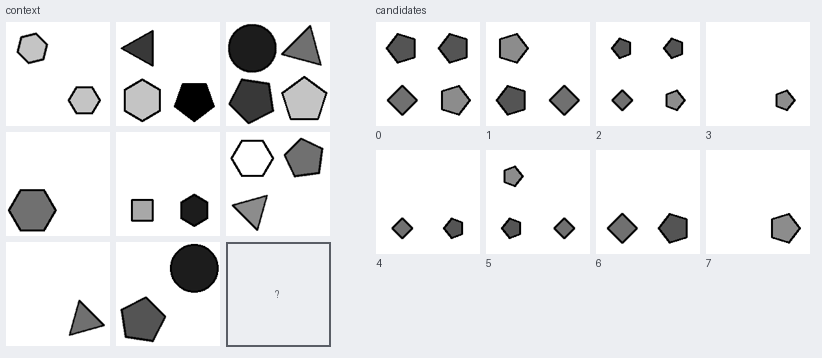

In [2]:
def show_puzzle(images, marks={}, s=104, g=6):
    W, H = 7 * s + 9 * g + 40, 3 * s + 4 * g + 22
    img = Image.new("RGB", (W, H), (236, 238, 242)); d = ImageDraw.Draw(img)
    d.text((g, 4), "context", fill=(60, 64, 72)); d.text((3 * s + 4 * g + 40, 4), "candidates", fill=(60, 64, 72))
    for p in range(9):
        x, y = g + p % 3 * (s + g), 22 + p // 3 * (s + g)
        if p < 8: img.paste(Image.fromarray(images[p]).resize((s, s)).convert("RGB"), (x, y))
        else: d.rectangle([x, y, x + s, y + s], outline=(90, 94, 102), width=2); d.text((x + s // 2 - 3, y + s // 2 - 6), "?", fill=(90, 94, 102))
    for c in range(8):
        x, y = 3 * s + 4 * g + 40 + c % 4 * (s + g), 22 + c // 4 * (s + 18 + g)
        img.paste(Image.fromarray(images[8 + c]).resize((s, s)).convert("RGB"), (x, y))
        rgb, label = marks.get(c, ((60, 64, 72), ""))
        if c in marks: d.rectangle([x - 3, y - 3, x + s + 2, y + s + 2], outline=rgb, width=4)
        d.text((x, y + s + 3), f"{c} {label}", fill=rgb)
    display(img)

CFG, IDX = "distribute_four", 303             # a fixed unseen puzzle, not picked for being solved
stem = f"{DATA}/{CFG}/RAVEN_{IDX}_val"
images, answer = np.load(stem + ".npz")["image"], int(np.load(stem + ".npz")["target"])
panels = B.parse(stem + ".xml", CFG)
print(f"RAVEN_{IDX}_val | {CFG} | answer: candidate {answer}")
show_puzzle(images)

## 2. The graph of this puzzle

The picture is read from the network PyNeuraLogic grounds for this puzzle (`FV.ground_graph`), not drawn
by hand. It shows one attribute, type: size and colour have identical copies of this graph, with the same
weights. The layers are merged: an object's facets `f0`, `f1`, `f2` are one node, a panel's `pt`, `pv1`,
`pv2`, `vF` one panel node.

**Nodes**
* *Facets* (circles): one per object and attribute, holding the value as a thermometer code (value v = first v of 10 bits on).
* *Panel nodes* (squares): per panel, component and attribute, the average of that component's facets.
  Number is a fourth attribute with panel nodes only, from the object count.
* *Row nodes* `rel r1`, `rel r2`: per complete row, "how the attribute changes along the row".
* `ctx`: the average of the two row nodes. `ans`: the answer, from `ctx` and panels (3,1), (3,2). `out`: the output.
* Positions have their own chain of the same shape (panel occupancy → row → answer), not drawn.

**Edges**
* facet ↔ facet: same attribute, objects at the **same position** in another column of the same row (a weight per column pair);
* facet ↔ its panel node, both ways, in every layer;
* panel nodes → their row node (a weight per column); row nodes → `ctx` → `ans`; panels (3,1), (3,2) → `ans` → `out`.
* Never: between attributes, between rows, or between objects at different positions.

The structural atoms (`obj`, `samepos`, `row`, ...) are *hidden*: they decide which neurons exist but add
nothing to a sum (visible, each added 1.0 to every component and hid the positions from the model).

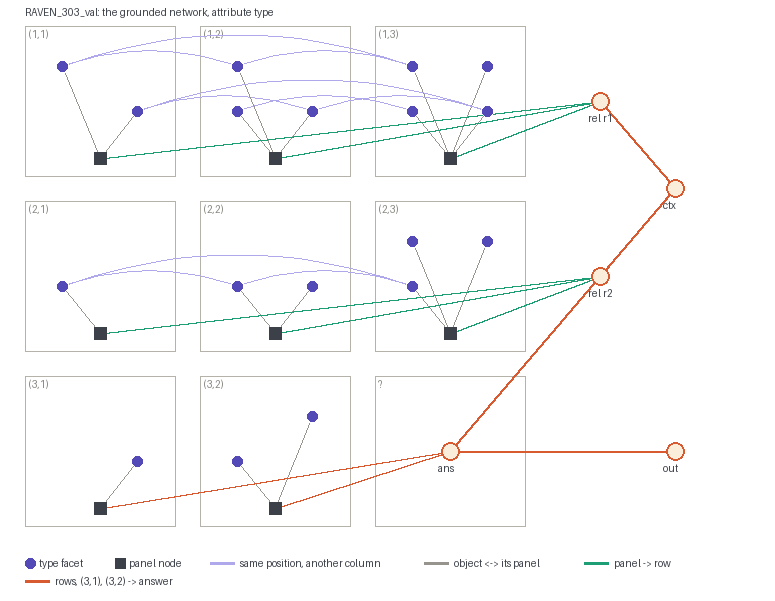

the whole network (all attributes and positions): 397 ground atoms, 742 atom-to-atom edges
  ans 4, ansp 1, ctx 4, ctxp 1, f0 54, f1 54, f2 54, fv 54, nm 8, oa 4, occ 8, op 1, out 1, pos 18, pt 32, puzzle 1, pv1 24, pv2 24, rel 8, relp 2, vF 32, vP 8
panel (1,1): [pos 4: type 3 size 2 colour 2]  [pos 1: type 3 size 2 colour 2]
panel (1,2): [pos 3: type 3 size 4 colour 2]  [pos 4: type 2 size 4 colour 9]  [pos 1: type 0 size 4 colour 7]
panel (1,3): [pos 4: type 2 size 5 colour 2]  [pos 1: type 4 size 5 colour 8]  [pos 3: type 2 size 5 colour 7]  [pos 2: type 0 size 5 colour 5]
panel (2,1): [pos 3: type 3 size 5 colour 5]
panel (2,2): [pos 3: type 1 size 2 colour 3]  [pos 4: type 3 size 2 colour 8]
panel (2,3): [pos 3: type 0 size 4 colour 4]  [pos 1: type 3 size 4 colour 0]  [pos 2: type 2 size 4 colour 5]
panel (3,1): [pos 4: type 0 size 4 colour 5]
panel (3,2): [pos 3: type 2 size 5 colour 6]  [pos 2: type 4 size 5 colour 8]


In [3]:
comp = B.comps(CFG)[0]
edges = FV.ground_graph(B.build_facet_template(32, 2, widths=WIDTHS),        # the structure only: weights do not matter
                        B.puzzle_facts(panels, "g") + B.facet_facts(panels, "therm", CFG) + [R.qcomp("g", comp)], "g")
display(FV.draw_network(panels, edges, "type", CFG, comp, title=f"RAVEN_{IDX}_val: the grounded network, attribute type"))
atoms = Counter(a[:a.find("(")] for a in {a for e in edges for a in e})
print(f"the whole network (all attributes and positions): {sum(atoms.values())} ground atoms, {len(edges)} atom-to-atom edges")
print("  " + ", ".join(f"{p} {n}" for p, n in sorted(atoms.items())))
for p in range(8):
    print(f"panel ({p // 3 + 1},{p % 3 + 1}): " + "  ".join(
        f"[pos {o['pos']}: type {o['type']} size {o['size']} colour {o['color']}]" for o in panels[p]))

## 3. The template, widths 32 → 64 → 128

The rules below are the whole model. `f0` projects each facet's code to 32, facet layer 1 is 64 wide, layer 2
and everything above it (panel values `vF`, row relation `rel`, context `ctx`, answer `ans`) 128. Where a
layer is wider than the one below, its residual is a learned projection. Attribute and component are
variables in every rule, so one set of weights serves type, size, colour and number, and both components.

In [4]:
model = B.build_facet_template(32, 2, shared=not args["per_attr_weights"], rows=not args["no_rows"], widths=WIDTHS,
                               hidden=not args.get("visible_selectors", False))
print(model)

f0(O, A) :- {32, 10} fv(O, A).
f0/2 [transformation=tanh]
pv1(P, C, A) :- *obj(P, O), *ocomp(O, C), {64, 32} f0(O, A). [aggregation=avg]
f1(O, A) :- *obj(P, O), *ocomp(O, C), {64, 64} pv1(P, C, A).
f1(O, A) :- *samepos(O1, O), *obj(P, O), *col(P, c1), *obj(Q, O1), *col(Q, c2), {64, 32} f0(O1, A). [aggregation=avg]
f1(O, A) :- *samepos(O1, O), *obj(P, O), *col(P, c1), *obj(Q, O1), *col(Q, c3), {64, 32} f0(O1, A). [aggregation=avg]
f1(O, A) :- *samepos(O1, O), *obj(P, O), *col(P, c2), *obj(Q, O1), *col(Q, c1), {64, 32} f0(O1, A). [aggregation=avg]
f1(O, A) :- *samepos(O1, O), *obj(P, O), *col(P, c2), *obj(Q, O1), *col(Q, c3), {64, 32} f0(O1, A). [aggregation=avg]
f1(O, A) :- *samepos(O1, O), *obj(P, O), *col(P, c3), *obj(Q, O1), *col(Q, c1), {64, 32} f0(O1, A). [aggregation=avg]
f1(O, A) :- *samepos(O1, O), *obj(P, O), *col(P, c3), *obj(Q, O1), *col(Q, c2), {64, 32} f0(O1, A). [aggregation=avg]
pv1/3 [transformation=tanh]
f1(O, A) :- {64, 32} f0(O, A).
f1/2 [transformation=norm]
pv2(P, C

In [5]:
model.build(Settings(optimizer=Adam(lr=args["lr"]), error_function=MSE(), iso_value_compression=False))
model.load(f"{CKPT}/template_best.bin")
weights = model.state_dict()["weights"] if "weights" in model.state_dict() else model.state_dict()
print("learned weight tensors:", len(weights), "| numbers:", sum(int(np.size(v)) for v in weights.values()))

learned weight tensors: 40 | numbers: 266528


## 4. Generating the answer

Every puzzle of val 300–399 in all seven constellations is grounded in one go (PyNeuraLogic builds a
model's dataset once); our puzzle is among them. One sample per component of the missing panel.

In [6]:
cfgs = list(B.POS_MAP)
data = B.load(DATA, cfgs, "val", 300, 100)
units, samples = [], []
for i, (pz, y, cfg) in enumerate(data):
    for k in B.comps(cfg):
        gid = f"v{i}{k}"
        target = B.facet_target(B.comp_objs(pz[8 + y], cfg, k))
        facts = B.puzzle_facts(pz, gid) + B.facet_facts(pz, "therm", cfg) + [R.qcomp(gid, k)]
        units.append((i, k)); samples.append(Sample(R.out(gid)[target.tolist()], facts))
built = list(model.build_dataset(Dataset(samples)))
outs = [dict() for _ in data]
for (i, k), o in zip(units, model.test(built)):
    outs[i][k] = np.asarray(o, dtype=float).flatten()
print(len(data), "puzzles,", len(built), "grounded samples")

def readable(spec):
    vals = lambda a: [v for v, c in enumerate(spec[a]) for _ in range(int(c))]
    return f"positions {list(map(int, spec['pos']))}  type {vals('type')}  size {vals('size')}  colour {vals('color')}"

ex = cfgs.index(CFG) * 100 + (IDX - 300)
for k, o in outs[ex].items():
    print(f"component {k}\n  generated: {readable(B.facet_decode(o))}"
          f"\n  answer:    {readable(B.decode(B.describe(B.comp_objs(panels[8 + answer], CFG, k))))}")

700 puzzles, 1100 grounded samples
component k0
  generated: positions [1, 2, 3, 4]  type [2, 2, 3, 3]  size [2, 2, 2, 2]  colour [2, 2, 3, 4]
  answer:    positions [1, 3, 4]  type [1, 2, 2]  size [2, 2, 2]  colour [4, 5, 6]


candidate 1: distance   2.429 #############   <- answer
candidate 0: distance   2.719 ##############
candidate 5: distance   4.429 ########################
candidate 6: distance   4.705 #########################
candidate 2: distance   4.718 #########################
candidate 7: distance   5.263 ############################
candidate 4: distance   6.705 ####################################
candidate 3: distance   7.263 ########################################
picked candidate 1 | answer 1 | correct


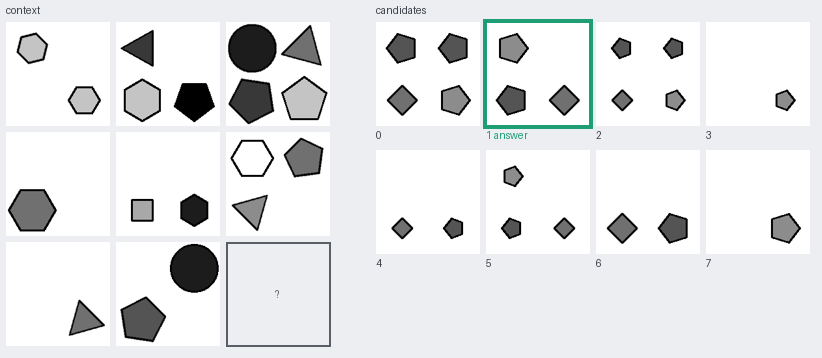

In [7]:
dist = np.array([sum(np.sum((o - B.facet_target(B.comp_objs(panels[8 + c], CFG, k))) ** 2)
                    for k, o in outs[ex].items()) for c in range(8)])
pick = int(np.argmin(dist))
for c in np.argsort(dist):
    print(f"candidate {c}: distance {dist[c]:7.3f} " + "#" * int(40 * dist[c] / dist.max()) + ("   <- answer" if c == answer else ""))
print(f"picked candidate {pick} | answer {answer} | {'correct' if pick == answer else 'wrong'}")
show_puzzle(images, {answer: ((29, 158, 117), "answer"), **({} if pick == answer else {pick: ((216, 90, 48), "picked")})})

## 5. Accuracy on these 700 unseen puzzles, and the training history

In [8]:
mse, exact, matched, ties, per = B.evaluate(outs, data, "therm")
print(f"{'constellation':40s} matched   (100 puzzles each)")
for cfg, (h, t) in per.items():
    print(f"{cfg:40s} {100 * h / t:6.1f}%")
print(f"{'all':40s} {100 * matched / len(data):6.1f}%   | generated exactly: {100 * exact['all'] / len(data):.1f}%"
      f" (type {100 * exact['type'] / len(data):.0f}, size {100 * exact['size'] / len(data):.0f},"
      f" colour {100 * exact['color'] / len(data):.0f}, positions {100 * exact['pos'] / len(data):.0f})")

constellation                            matched   (100 puzzles each)
center_single                             100.0%
distribute_four                            95.0%
distribute_nine                            89.0%
left_center_single_right_center_single    100.0%
up_center_single_down_center_single       100.0%
in_center_single_out_center_single        100.0%
in_distribute_four_out_center_single       99.0%
all                                        97.6%   | generated exactly: 67.7% (type 78, size 77, colour 76, positions 80)


In [9]:
hist = json.load(open(f"{CKPT}/history.json"))
pct = lambda h, s: 100 * h[s]["matched"] / sum(t for _, t in h[s]["per_constellation"].values())
short = {c: c.replace("_center_single", "").replace("center_single", "center")[:10] for c in cfgs}
print("epoch | train  val0-299  val300+ | " + " ".join(f"{short[c]:>10s}" for c in cfgs) + "   (matched %, val 300-1299)")
for h in hist:
    print(f"{h['epoch']:5d} | {pct(h, 'train'):5.1f}  {pct(h, 'sel'):8.1f}  {pct(h, 'unseen'):7.1f} | " + " ".join(
        f"{100 * h['unseen']['per_constellation'][c][0] / h['unseen']['per_constellation'][c][1]:10.1f}" for c in cfgs))
print(f"best epoch so far (val 0-299): {best['epoch']}")

epoch | train  val0-299  val300+ |     center distribute distribute left_right    up_down     in_out in_distrib   (matched %, val 300-1299)
    5 |  93.3      93.2     92.9 |       97.9       89.0       72.3       97.9       97.5       98.8       96.8
   10 |  95.5      94.8     95.2 |       97.9       93.0       83.6       98.1       98.3       99.4       96.0
   15 |  97.0      96.2     96.3 |       98.4       94.2       87.1       99.2       98.7       99.1       97.2
   20 |  96.5      96.0     95.9 |       98.3       93.8       86.4       99.1       98.8       98.8       96.0
   25 |  97.8      97.0     97.1 |       98.9       95.3       88.4       99.6       99.7       99.9       97.7
   30 |  98.0      97.1     97.0 |       99.2       94.2       88.7       99.9       99.4       99.9       97.9
   35 |  97.2      96.5     96.6 |       98.5       94.4       88.6       99.4       98.8       99.4       97.0
   40 |  97.4      96.5     96.6 |       99.3       93.3       88.0       99

**Reading the numbers.** Inputs are XML ground-truth attributes (perception is assumed perfect);
accuracies are on validation puzzles, the test split is untouched. *Matched* = the candidate closest to the
generated answer is the correct one (chance 12.5%); *generated exactly* = every component's decoded
positions and value counts equal the answer's. Earlier results (val 300–1299): facet model dim 32 on all
constellations 83.8%; widths 32 → 64 → 128 on distribute_nine alone about 91% (dim 32: 78%).

## 6. Copy links, on I-RAVEN-X 3×10 (values 0–49)

I-RAVEN-X (IBM's generator) has rows of 10 panels, one object per panel and values 0–49. The data is
symbolic: there are no images. Without copy links the answer sees rows 1–2 only through the row summary
`ctx` and 128 tanh units, so it misses answers that *are* one particular context value (Constant,
Distribute) and loses precision on large values. **Copy links** (`--copy-links`, notes §20) add a direct
path: every context panel's own code, scaled to ±4, enters the output logits, multiplied by a gate that
the answer node computes, one gate per panel:

    gate(p_i, C, A) :- ans(C, A)                       weights per panel p_i
    gate(p_i, C, A) :- puzzle(G), pc(p_i, C, A)        bias, starts at -6: the gates start nearly closed
    copy(C, A)      :- gate(P, C, A) * pc(P, C, A)     elementwise, summed over the panels
    oa(G, A)        :- copy(C, A)                      added to the output logits

Weights: `experiments/facet_iravenx_n10_m50_copy` (60 epochs, picked epoch 55) and, without copy links,
`experiments/facet_iravenx_n10_m50` (picked epoch 35). Both trained on puzzles 0–5999 with the epoch
picked on 6000–6299; below are the first 300 unseen puzzles (6300+).

In [10]:
IRX = "data/iravenx/center_single_shuffle_n_10_maxval_50.json"
xdata = B.load_iravenx(IRX, 6300, 300)
B.configure(n_cols=10, maxval=50)               # rows of 10 panels, 50-bit codes (sections 1-5 used I-RAVEN's defaults)
xrules = [B._IRAVENX[IRX][str(6300 + i)]["rules"][0] for i in range(len(xdata))]
XI = 0                                           # puzzle 6300, the first unseen one
xp, xy, _ = xdata[XI]
print(f"puzzle {6300 + XI} | answer: candidate {xy} | rules: " + ", ".join(f"{a} {xrules[XI][a]}" for a in ("Type", "Size", "Color")))
for a in B.FACET_ATTRS:
    print(a + "".join(f"\n   row {r + 1}: " + " ".join(f"{xp[r * 10 + c][0][a]:2d}" if r * 10 + c < B.N_CTX else " ?"
                                                    for c in range(10)) for r in range(3)))
print("candidates (type, size, colour): " + "  ".join(f"{c}: {tuple(xp[B.N_CTX + c][0][a] for a in B.FACET_ATTRS)}" for c in range(8)))

puzzle 6300 | answer: candidate 4 | rules: Type Constant, Size Distribute_Three, Color Constant
type
   row 1: 39 39 39 39 39 39 39 39 39 39
   row 2: 39 39 39 39 39 39 39 39 39 39
   row 3: 35 35 35 35 35 35 35 35 35  ?
size
   row 1:  5 24 30 11  3 28 27 43 33 22
   row 2: 22  5 24 30 11  3 28 27 43 33
   row 3: 33 22  5 24 30 11  3 28 27  ?
color
   row 1: 45 45 45 45 45 45 45 45 45 45
   row 2: 36 36 36 36 36 36 36 36 36 36
   row 3: 40 40 40 40 40 40 40 40 40  ?
candidates (type, size, colour): 0: (34, 43, 40)  1: (35, 34, 40)  2: (34, 34, 3)  3: (34, 34, 40)  4: (35, 43, 40)  5: (35, 43, 3)  6: (34, 43, 3)  7: (35, 34, 3)


In [11]:
def load_facet(ckpt, copy):
    a = json.load(open(f"{ckpt}/best.json"))["args"]
    m = B.build_facet_template(32, 2, widths=[int(w) for w in a["widths"].split(",")], copy=copy)
    m.build(Settings(optimizer=Adam(lr=a["lr"]), error_function=MSE(), iso_value_compression=False))
    m.load(f"{ckpt}/template_best.bin")
    return m

xmodels = {"plain": load_facet("experiments/facet_iravenx_n10_m50", False),
           "copy links": load_facet("experiments/facet_iravenx_n10_m50_copy", True)}
lines = str(B.build_facet_template(32, 2, widths=WIDTHS, copy=True)).splitlines()
print("the rules copy links add (shown for panel p0):")
for l in lines:
    if l.startswith(("gate(p0,", "gate/", "copy")) or (l.startswith("oa") and "copy" in l):
        print("  " + re.sub(r"\[(-6\.0, )+-6\.0\]", "[-6.0 x 50]", l))
print(f"the two gate rules repeat for each of the {B.N_CTX} context panels; {len(lines)} lines in the whole template")

the rules copy links add (shown for panel p0):
  gate(p0, C, A) :- {50, 128} ans(C, A).
  gate(p0, C, A) :- [-6.0 x 50] puzzle(G), *qcomp(G, C), *pc(p0, C, A).
  copy(C, A) :- gate(P, C, A), pc(P, C, A). [combination=elproduct, aggregation=sum]
  oa(G, A) :- *qcomp(G, C), copy(C, A).
  gate/3 [transformation=sigmoid]
  copy/2 [transformation=identity]
the two gate rules repeat for each of the 29 context panels; 286 lines in the whole template


In [12]:
xbuilt, xouts = {}, {}
for name, m in xmodels.items():
    samples = [Sample(R.out(f"x{i}")[B.facet_target(p[B.N_CTX + y]).tolist()],
                      B.puzzle_facts(p, f"x{i}") + B.facet_facts(p, "therm", "center_single", copy=name != "plain")
                      + [R.qcomp(f"x{i}", "k0")]) for i, (p, y, _) in enumerate(xdata)]
    xbuilt[name] = list(m.build_dataset(Dataset(samples)))
    xouts[name] = [{"k0": np.asarray(o, dtype=float).flatten()} for o in m.test(xbuilt[name])]
for name in xmodels:
    print(f"{name:10s} generated: {readable(B.facet_decode(xouts[name][XI]['k0']))}")
print(f"{'':10s} answer:    {readable(B.decode(B.describe(xp[B.N_CTX + xy])))}")

xmodels["copy links"].test([xbuilt["copy links"][XI]])      # the sample's neurons now hold this puzzle's values
gates = {a: FV.gate_means(xbuilt["copy links"][XI], a) for a in B.FACET_ATTRS}
print(f"\ncopy gates of puzzle {6300 + XI} (mean over the 50 bits), per context panel:")
for a in B.FACET_ATTRS:
    print(a + "".join(f"\n   row {r + 1}: " + " ".join(f"{gates[a][r * 10 + c]:.2f}" if r * 10 + c < B.N_CTX else "   ?"
                                                    for c in range(10)) for r in range(3)))

plain      generated: positions [0]  type [36]  size [43]  colour [40]
copy links generated: positions [0]  type [35]  size [43]  colour [40]
           answer:    positions [0]  type [35]  size [43]  colour [40]

copy gates of puzzle 6300 (mean over the 50 bits), per context panel:
type
   row 1: 0.01 0.08 0.00 0.01 0.02 0.00 0.03 0.08 0.01 0.03
   row 2: 0.16 0.00 0.00 0.00 0.00 0.00 0.00 0.02 0.12 0.03
   row 3: 0.11 0.22 0.38 0.19 0.34 0.33 0.33 0.30 0.62    ?
size
   row 1: 0.00 0.97 0.01 0.02 0.01 0.02 0.00 0.95 0.01 0.00
   row 2: 0.93 0.01 0.00 0.00 0.01 0.01 0.00 0.00 0.92 0.02
   row 3: 0.00 0.00 0.01 0.00 0.01 0.00 0.01 0.00 0.01    ?
color
   row 1: 0.00 0.05 0.00 0.01 0.01 0.00 0.02 0.06 0.00 0.03
   row 2: 0.15 0.00 0.00 0.00 0.00 0.00 0.00 0.02 0.09 0.02
   row 3: 0.10 0.21 0.37 0.19 0.30 0.31 0.29 0.26 0.60    ?


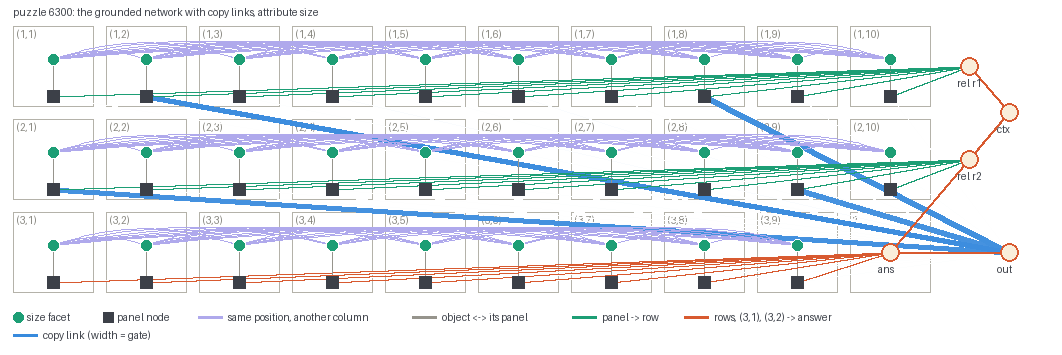

size gates above 0.5: (1,2) gate 0.97, size 24, (1,8) gate 0.95, size 43, (2,1) gate 0.93, size 22, (2,9) gate 0.92, size 43 | the answer's size: 43


In [13]:
xedges = FV.ground_graph(B.build_facet_template(32, 2, widths=WIDTHS, copy=True),
                         B.puzzle_facts(xp, "g") + B.facet_facts(xp, "therm", "center_single", copy=True) + [R.qcomp("g", "k0")], "g")
display(FV.draw_network(xp, xedges, "size", gates=gates["size"], s=80,
                        title=f"puzzle {6300 + XI}: the grounded network with copy links, attribute size"))
print(f"size gates above 0.5: " + ", ".join(f"({p // 10 + 1},{p % 10 + 1}) gate {v:.2f}, size {xp[p][0]['size']}"
                                            for p, v in gates["size"].items() if v > 0.5)
      + f" | the answer's size: {xp[B.N_CTX + xy][0]['size']}")

In [14]:
n, key = len(xdata), {"type": "Type", "size": "Size", "color": "Color"}
print(f"{n} unseen puzzles | matched | generated exactly: all   type  size  colour")
for name in xmodels:
    _, exact, matched, _, _ = B.evaluate(xouts[name], xdata, "therm")
    print(f"{name:20s} {100 * matched / n:6.1f}%  | {100 * exact['all'] / n:24.1f}  " + "  ".join(f"{100 * exact[a] / n:5.1f}" for a in B.FACET_ATTRS))
hits, tot = Counter(), Counter()
for i, (p, y, _) in enumerate(xdata):
    want = B.decode(B.describe(p[B.N_CTX + y]))
    got = {name: B.facet_decode(xouts[name][i]["k0"]) for name in xmodels}
    for a in B.FACET_ATTRS:
        tot[xrules[i][key[a]]] += 1
        for name in xmodels:
            hits[name, xrules[i][key[a]]] += got[name][a] == want[a]
print("\ngenerated exactly, per rule (type, size and colour together):")
for rule in sorted(tot):
    print(f"   {rule:17s} " + "   ".join(f"{name} {100 * hits[name, rule] / tot[rule]:5.1f}%" for name in xmodels) + f"   ({tot[rule]} instances)")

300 unseen puzzles | matched | generated exactly: all   type  size  colour
plain                  86.3%  |                     17.7   57.7   55.7   55.0
copy links             98.0%  |                     62.7   95.3   81.7   81.3

generated exactly, per rule (type, size and colour together):
   Arithmetic        plain  25.2%   copy links  31.9%   (135 instances)
   Constant          plain  94.1%   copy links 100.0%   (271 instances)
   Distribute_Three  plain  11.5%   copy links  96.9%   (260 instances)
   Progression       plain  79.5%   copy links  89.3%   (234 instances)


**Reading section 6.** *Matched* and *generated exactly* as in section 5; notes §20.3 has the same
comparison on all 1000 unseen puzzles (85.4% → 97.8% matched).
* The gain is where the answer is a value already in the context: Distribute is generated exactly 11.5% →
  96.9% of the time, Constant 94.1% → 100%. Arithmetic hardly moves: its answer is a sum, not a copy.
* Puzzle 6300, size: the rows shift by +1 and the answer is 43. The four open gates are the panels that
  hold the answer under either shift: (1,8) and (2,9) hold 43 (shift +1), (1,2) and (2,1) hold 24 and 22
  (shift −1). The gates do not choose the direction. The copied thermometer codes agree below 22 and
  above 43, and between them they mostly cancel, which leaves those bits to the path without copies.
* Type and colour follow Constant here, so the answer equals the other panels of row 3: their gates open
  partly (0.1–0.6), the rows 1–2 gates stay near 0.
* The gates are per panel, so they are learned by address. That breaks the symmetry of rows 1 and 2
  (notes §21.5); gates chosen by content and row role (`--copy-gates content`) keep it, at 94.9%.